To do itime complexity, we're just gonna graph them into log-log plot. Y is execution time in seconds, and X... I'm not sure yet. Either No. of nodes or No. of edges. 

In [49]:
import csv
import numpy as np
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [2]:
algos = {"coach": [150, 175, 200, 225], "demon": [0, 25, 50, 75]}
node_counts = [1024, 2048, 4096, 8192, 16384]
m_values = [8, 16, 32, 64, 128, 256]

In [23]:
def get_values_from_file(filename: str):
    try:
        with open(filename) as f:
            reader = csv.reader(f, delimiter="\t")
            first_row = next(reader)
        return [float(val) for val in first_row]
    except FileNotFoundError:
        print(filename, "doesn't exist.")
        return [-1, -1, -1, -1]

In [13]:
def params_to_filename(a, p, n, m):
    return f"../out/{a}/{p}/scale_free/report-n-{n}-m-{m}.txt"

In [16]:
get_values_from_file(params_to_filename("coach", "150", "1024", "8"))

[0.14515120908617973, 8128.0, 1024.0, 0.015518084066471163]

In [ ]:
def get_time_per_node(n : int):
    values = {}
    for algo, params in algos.items():
        values[algo] = {}
        for param in params:
            values[algo][param] = {}
            for m in m_values:
                values[algo][param][m] = get_values_from_file(params_to_filename(algo, param, n, m))
    return values

In [42]:
def to_X_and_y(v : dict, index_of_X : int):
    X = []
    y = []
    for _, vals in v.items():
        X.append(vals[index_of_X])
        y.append(vals[0])
    return X,y

In [54]:
values = get_time_per_node(16384)
to_X_and_y(values['coach'][150], 1)

../out/coach/150/scale_free/report-n-16384-m-256.txt doesn't exist.
../out/coach/175/scale_free/report-n-16384-m-128.txt doesn't exist.
../out/coach/175/scale_free/report-n-16384-m-256.txt doesn't exist.
../out/coach/200/scale_free/report-n-16384-m-16.txt doesn't exist.
../out/coach/200/scale_free/report-n-16384-m-256.txt doesn't exist.
../out/coach/225/scale_free/report-n-16384-m-256.txt doesn't exist.
../out/demon/0/scale_free/report-n-16384-m-256.txt doesn't exist.
../out/demon/25/scale_free/report-n-16384-m-8.txt doesn't exist.
../out/demon/25/scale_free/report-n-16384-m-32.txt doesn't exist.
../out/demon/25/scale_free/report-n-16384-m-256.txt doesn't exist.
../out/demon/50/scale_free/report-n-16384-m-32.txt doesn't exist.
../out/demon/50/scale_free/report-n-16384-m-256.txt doesn't exist.
../out/demon/75/scale_free/report-n-16384-m-32.txt doesn't exist.
../out/demon/75/scale_free/report-n-16384-m-256.txt doesn't exist.


([131008.0, 261888.0, 523264.0, 1044480.0, 2080768.0, -1],
 [4.153374630957842,
  21.064612928777933,
  146.5951844751835,
  1303.0489978082478,
  4698.718204446137,
  -1])

[  2.63063126 -29.61955327]


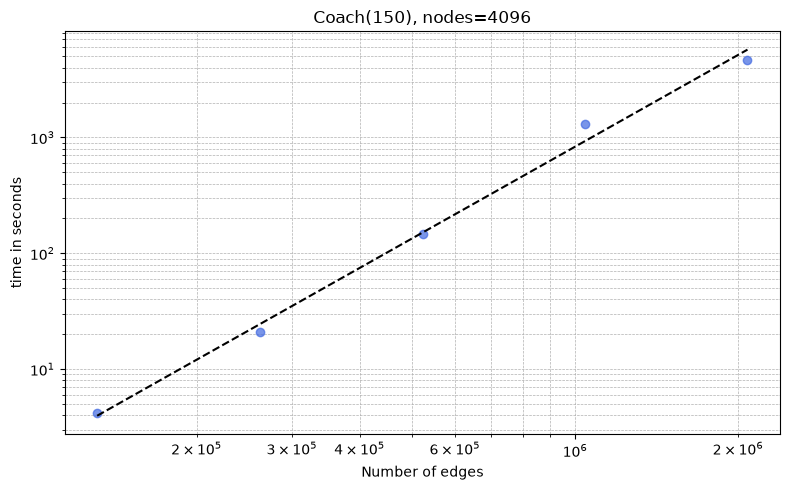

In [ ]:
X, y = to_X_and_y(values['coach'][150], 1)
X = np.delete(X, -1)
y = np.delete(y, -1)

logX = np.log(X)
logy = np.log(y)

coef = np.polyfit(logX, logy, 1)
print(coef)
poly1d_fn = np.poly1d(coef)

plt.figure(figsize=(8, 5))
plt.loglog(X, y, marker="o", linestyle="None", alpha=0.7, color="royalblue")
plt.plot(X, np.exp(poly1d_fn(logX)), '--k')
plt.grid(True, which="both", linestyle="--", linewidth=0.5)
plt.title("Coach(150), nodes=4096")
plt.ylabel("time in seconds")
plt.xlabel("Number of edges")
plt.tight_layout()
plt.show()

In [46]:
print([2**x for x in range(10, 20)])

[1024, 2048, 4096, 8192, 16384, 32768, 65536, 131072, 262144, 524288]
